# **Taller 10: Perceptrón multicapa para clasificar dígitos escritos a mano**
### Inteligencia Artificial ELP 8012 - Universidad del Norte - Profesor: Eduardo Zurek, PH.D. 
### **Grupo:** Natalia Carpintero, Paula Núñez e Isabella Arrieta.

En este cuaderno diseñamos, entrenamos y evaluamos una **Red Neuronal Artificial Multicapa (MLP)** que
clasifica imágenes de dígitos (0 a 9) del conjunto `digits` de scikit-learn. Seguimos la metodología del
cuaderno de referencia `02_MLP_EZ_datos_sinteticos.ipynb`:

1. Explorar el conjunto de datos.
2. Separar **entrenamiento / validación / prueba** de forma estratificada.
3. Entrenar cuatro MLP idénticos que **solo difieren en la función de activación** de la capa oculta:
   `identity`, `logistic`, `tanh` y `relu`.
4. Comparar precisión, convergencia y **tiempo de entrenamiento**.
5. Elegir la activación con el conjunto de validación y evaluarla una sola vez en prueba.
6. Concluir cuál conviene usar.

In [ ]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, log_loss,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
)

SEMILLA = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
print("Versiones:", "NumPy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)

Versiones: NumPy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0


## 1. El conjunto de datos `digits`

`load_digits` contiene **1797 imágenes** de dígitos manuscritos de **8 × 8 píxeles** en escala de grises.
Cada píxel toma un valor entero entre 0 (blanco) y 16 (negro). Al aplanar la imagen obtenemos un vector de
**64 características** por muestra. La etiqueta es el dígito (0 a 9), es decir, un problema de
**clasificación multiclase con 10 clases**.

In [ ]:
digits = load_digits()
X, y = digits.data, digits.target
print("Forma de X:", X.shape, "| Forma de y:", y.shape)
print("Rango de los píxeles:", X.min(), "a", X.max())
print("¿Valores faltantes?", bool(np.isnan(X).any()))

distribucion = pd.DataFrame({"Dígito": np.arange(10), "Cantidad": np.bincount(y)})
distribucion["Porcentaje"] = 100 * distribucion["Cantidad"] / len(y)
print()
print(distribucion.round(2).to_string(index=False))

Forma de X: (1797, 64) | Forma de y: (1797,)
Rango de los píxeles: 0.0 a 16.0
¿Valores faltantes? False

 Dígito  Cantidad  Porcentaje
      0       178        9.91
      1       182       10.13
      2       177        9.85
      3       183       10.18
      4       181       10.07
      5       182       10.13
      6       181       10.07
      7       179        9.96
      8       174        9.68
      9       180       10.02


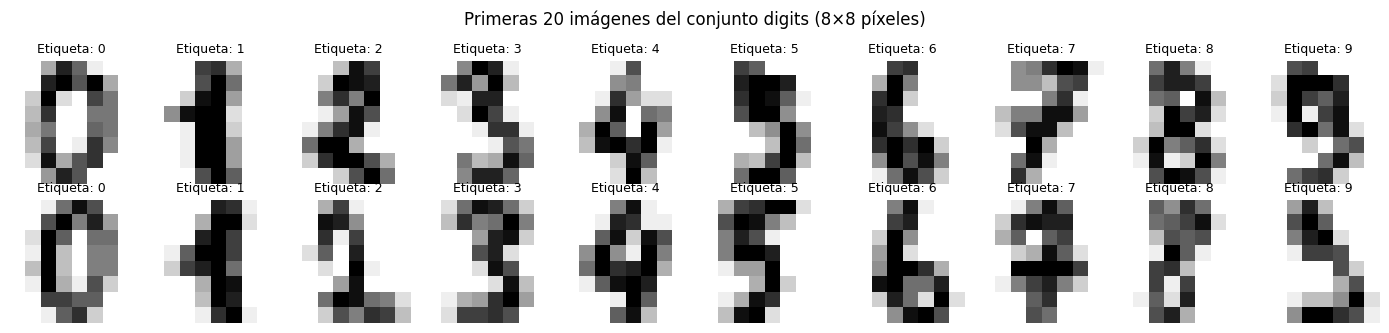

In [ ]:
fig, ejes = plt.subplots(2, 10, figsize=(14, 3.4))
for k, eje in enumerate(ejes.ravel()):
    eje.imshow(digits.images[k], cmap="gray_r")
    eje.set_title(f"Etiqueta: {y[k]}", fontsize=9)
    eje.axis("off")
plt.suptitle("Primeras 20 imágenes del conjunto digits (8×8 píxeles)")
plt.tight_layout()
plt.show()

Las clases están **casi balanceadas** (cada dígito tiene entre ~9 % y ~10 % de las muestras), así que la
*accuracy* es una métrica razonable aquí. Aun así, también reportamos *balanced accuracy*, *F1 macro* y
*log loss*, como en el cuaderno de referencia.

## 2. Entrenamiento, validación y prueba

Hacemos particiones **estratificadas** (mantienen la proporción de cada dígito): 60 % entrenamiento,
20 % validación y 20 % prueba.

- **Entrenamiento**: se usa para ajustar los pesos de la red.
- **Validación**: se usa para *elegir* la función de activación.
- **Prueba**: se consulta una sola vez, al final, para estimar el desempeño real del modelo elegido.

In [ ]:
X_des, X_test, y_des, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_train, X_val, y_train, y_val = train_test_split(
    X_des, y_des, test_size=0.25, stratify=y_des, random_state=SEMILLA)

resumen = pd.DataFrame({
    "Partición": ["Entrenamiento", "Validación", "Prueba"],
    "Muestras": [len(y_train), len(y_val), len(y_test)],
})
print(resumen.to_string(index=False))
print("\nMuestras por dígito en cada partición:")
print(pd.DataFrame({"Entrenamiento": np.bincount(y_train),
                    "Validación": np.bincount(y_val),
                    "Prueba": np.bincount(y_test)}).T.to_string())

    Partición  Muestras
Entrenamiento      1077
   Validación       360
       Prueba       360

Muestras por dígito en cada partición:
                 0    1    2    3    4    5    6    7    8    9
Entrenamiento  106  109  107  109  109  109  109  107  104  108
Validación      36   37   35   37   36   36   36   36   35   36
Prueba          36   36   35   37   36   37   36   36   35   36


## 3. Funciones de activación

Cada neurona calcula una suma ponderada de sus entradas, $z = \mathbf{w}\cdot\mathbf{x} + b$, y le aplica una
**función de activación** $f(z)$. Es la que decide si la red puede aprender relaciones **no lineales**.
Comparamos las cuatro que pide el taller:

| Activación | Fórmula | Rango de salida |
| --- | --- | --- |
| `identity` | $f(z)=z$ | $(-\infty,\ \infty)$ |
| `logistic` (sigmoide) | $f(z)=\dfrac{1}{1+e^{-z}}$ | $(0,\ 1)$ |
| `tanh` | $f(z)=\tanh(z)=\dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ | $(-1,\ 1)$ |
| `relu` | $f(z)=\max(0,\ z)$ | $[0,\ \infty)$ |

**`identity`.** No modifica la entrada. Una red con activación identidad compone capas afines, y la
composición de funciones lineales es lineal: aunque tenga muchas neuronas ocultas, equivale a **un modelo
lineal** (una regresión logística multinomial). Es la línea base para saber cuánta no linealidad aporta
realmente el problema.

**`logistic` (sigmoide).** Comprime cualquier valor en el intervalo (0, 1). Es suave y diferenciable, pero
**satura**: para $|z|$ grandes su derivada se acerca a 0 (*gradiente que se desvanece*), lo que vuelve lento
el aprendizaje, y su salida no está centrada en cero.

**`tanh` (tangente hiperbólica).** Parecida a la sigmoide pero con salida en (−1, 1) **centrada en cero**, lo
que suele facilitar la optimización. También satura en los extremos, por lo que comparte el problema del
gradiente que se desvanece, aunque en menor grado.

**`relu` (*Rectified Linear Unit*).** Devuelve 0 si $z<0$ y $z$ si $z\geq 0$. Es **muy barata de calcular**,
no satura para valores positivos (su derivada es 1) y produce activaciones dispersas. Su desventaja es que
las neuronas con $z<0$ siempre pueden quedar «muertas» (gradiente 0) y que no es diferenciable en $z=0$.

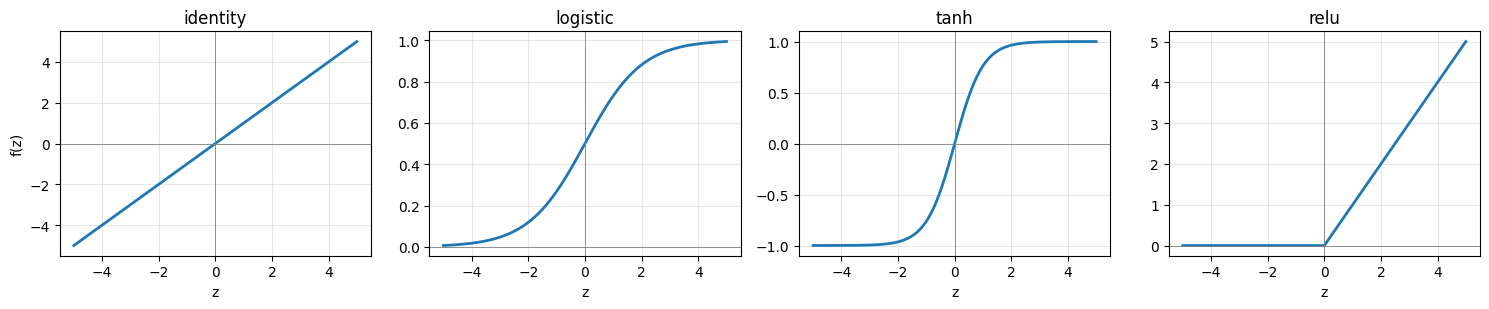

In [ ]:
z = np.linspace(-5, 5, 400)
funciones = {
    "identity": z,
    "logistic": 1 / (1 + np.exp(-z)),
    "tanh": np.tanh(z),
    "relu": np.maximum(0, z),
}
fig, ejes = plt.subplots(1, 4, figsize=(15, 3.2), sharex=True)
for eje, (nombre, valores) in zip(ejes, funciones.items()):
    eje.plot(z, valores, linewidth=2)
    eje.axhline(0, color="gray", linewidth=0.6)
    eje.axvline(0, color="gray", linewidth=0.6)
    eje.set_title(nombre)
    eje.set_xlabel("z")
    eje.grid(alpha=0.3)
ejes[0].set_ylabel("f(z)")
plt.tight_layout()
plt.show()

## 4. Arquitectura, entrenamiento y métricas

Todos los modelos tienen la misma arquitectura:

- **Entrada**: 64 neuronas (los píxeles).
- **Capa oculta**: 64 neuronas con la activación que se quiere comparar.
- **Salida**: 10 neuronas con **softmax** (una probabilidad por dígito). La salida es fija; solo cambia la
  activación oculta.

Los demás hiperparámetros se mantienen **constantes** para que la comparación sea justa:
solver `lbfgs`, `alpha=1e-4` (regularización L2), `tol=1e-6`, `max_iter=2000` y la misma semilla. Cada modelo es
un `Pipeline` con `StandardScaler` + `MLPClassifier`, de modo que el escalador se ajusta **solo con
entrenamiento** (sin filtración de información de validación o prueba).

Métricas: **accuracy**, **balanced accuracy**, **F1 macro**, **log loss** (calidad de las probabilidades,
menor es mejor), número de **iteraciones**, advertencias de **convergencia** y **tiempo de entrenamiento**.

In [ ]:
def construir_mlp(activacion):
    return Pipeline([
        ("escalador", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=(64,), activation=activacion, solver="lbfgs",
            alpha=1e-4, tol=1e-6, max_iter=2000, max_fun=50000,
            random_state=SEMILLA)),
    ])

def evaluar(modelo, X_eval, y_eval):
    pred = modelo.predict(X_eval)
    proba = modelo.predict_proba(X_eval)
    return {
        "Accuracy": accuracy_score(y_eval, pred),
        "Balanced accuracy": balanced_accuracy_score(y_eval, pred),
        "F1 macro": f1_score(y_eval, pred, average="macro"),
        "Log loss": log_loss(y_eval, proba, labels=modelo.classes_),
    }

# Referencia trivial: predecir siempre la clase más frecuente
referencia = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Referencia (clase mayoritaria) en validación:")
print(pd.Series(evaluar(referencia, X_val, y_val)).round(4).to_string())

Referencia (clase mayoritaria) en validación:
Accuracy              0.1028
Balanced accuracy     0.1000
F1 macro              0.0186
Log loss             32.3392


## 5. Comparación de las cuatro activaciones en validación

Entrenamos los cuatro modelos midiendo el tiempo de cada `fit`. Registramos también si el optimizador
terminó por **convergencia** o porque alcanzó el límite de iteraciones.

In [ ]:
modelos, filas, avisos_por_modelo = {}, [], {}
for activacion in ["identity", "logistic", "tanh", "relu"]:
    modelo = construir_mlp(activacion)
    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(X_train, y_train)
    segundos = time.perf_counter() - inicio
    mensajes = [str(a.message) for a in avisos if issubclass(a.category, ConvergenceWarning)]
    ent = evaluar(modelo, X_train, y_train)
    val = evaluar(modelo, X_val, y_val)
    filas.append({
        "Activación": activacion,
        "Accuracy train": ent["Accuracy"],
        "Accuracy val": val["Accuracy"],
        "Balanced acc. val": val["Balanced accuracy"],
        "F1 macro val": val["F1 macro"],
        "Log loss val": val["Log loss"],
        "Iteraciones": modelo.named_steps["mlp"].n_iter_,
        "Sin converger": bool(mensajes),
        "Segundos": segundos,
    })
    modelos[activacion] = modelo
    avisos_por_modelo[activacion] = mensajes
    print(f"Entrenado: {activacion:9s} | iteraciones: {modelo.named_steps['mlp'].n_iter_:5d} "
          f"| segundos: {segundos:7.3f} | sin converger: {bool(mensajes)}")

resultados = pd.DataFrame(filas).set_index("Activación")
print("\nResultados (columnas 'train' en entrenamiento; las demás en validación):")
print(resultados.round(4).to_string())

Entrenado: identity  | iteraciones:    24 | segundos:   0.044 | sin converger: False
Entrenado: logistic  | iteraciones:    44 | segundos:   0.089 | sin converger: False


Entrenado: tanh      | iteraciones:    19 | segundos:   0.041 | sin converger: False


Entrenado: relu      | iteraciones:    23 | segundos:   0.051 | sin converger: False

Resultados (columnas 'train' en entrenamiento; las demás en validación):
            Accuracy train  Accuracy val  Balanced acc. val  F1 macro val  Log loss val  Iteraciones  Sin converger  Segundos
Activación                                                                                                                   
identity               1.0        0.9528             0.9527        0.9525        0.5020           24          False    0.0435
logistic               1.0        0.9750             0.9750        0.9752        0.1042           44          False    0.0886
tanh                   1.0        0.9667             0.9665        0.9667        0.1345           19          False    0.0412
relu                   1.0        0.9611             0.9609        0.9611        0.1905           23          False    0.0511


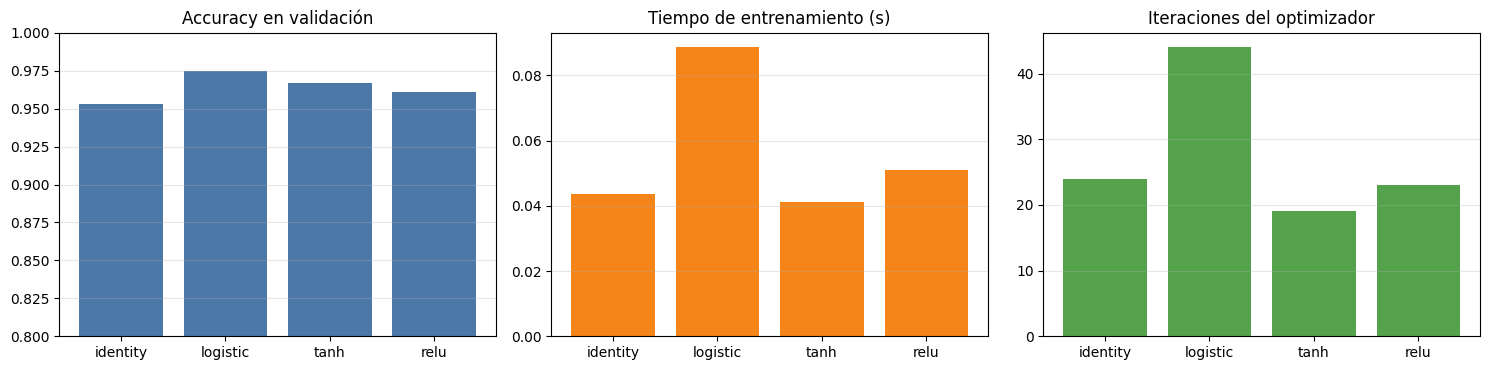

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
nombres = resultados.index.tolist()
ejes[0].bar(nombres, resultados["Accuracy val"], color="#4C78A8")
ejes[0].set_title("Accuracy en validación")
ejes[0].set_ylim(0.8, 1.0)
ejes[1].bar(nombres, resultados["Segundos"], color="#F58518")
ejes[1].set_title("Tiempo de entrenamiento (s)")
ejes[2].bar(nombres, resultados["Iteraciones"], color="#54A24B")
ejes[2].set_title("Iteraciones del optimizador")
for eje in ejes:
    eje.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 5.1. Estabilidad: repetición con varias semillas

Con una sola semilla, el tiempo y la precisión de cada activación pueden ser una casualidad (la inicialización
de pesos es aleatoria). Para dar más solidez al análisis repetimos el entrenamiento con **5 semillas distintas**
de inicialización, **siempre con las mismas particiones** y usando únicamente **entrenamiento y validación**
(la prueba sigue sin tocarse).

In [ ]:
registros = []
for semilla in range(5):
    for activacion in ["identity", "logistic", "tanh", "relu"]:
        m = construir_mlp(activacion)
        m.set_params(mlp__random_state=semilla)
        inicio = time.perf_counter()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            m.fit(X_train, y_train)
        registros.append({
            "Activación": activacion,
            "Accuracy val": accuracy_score(y_val, m.predict(X_val)),
            "Iteraciones": m.named_steps["mlp"].n_iter_,
            "Segundos": time.perf_counter() - inicio,
        })

repeticiones = pd.DataFrame(registros)
estabilidad = repeticiones.groupby("Activación").agg(
    acc_media=("Accuracy val", "mean"), acc_desv=("Accuracy val", "std"),
    iter_media=("Iteraciones", "mean"),
    seg_media=("Segundos", "mean"), seg_desv=("Segundos", "std"),
).loc[["identity", "logistic", "tanh", "relu"]]
print("Media y desviación estándar sobre 5 semillas (validación):")
print(estabilidad.round(4).to_string())

Media y desviación estándar sobre 5 semillas (validación):
            acc_media  acc_desv  iter_media  seg_media  seg_desv
Activación                                                      
identity       0.9517    0.0046        23.6     0.0403    0.0050
logistic       0.9800    0.0050        42.0     0.1056    0.0144
tanh           0.9728    0.0023        20.4     0.0445    0.0082
relu           0.9689    0.0072        22.2     0.0493    0.0017


## 6. Selección del modelo

La regla se fija **antes** de mirar la prueba: se escoge la activación con mayor *balanced accuracy* de
validación; en caso de empate, menor *log loss*; si persiste, orden alfabético. Después, el tiempo de
entrenamiento se usa para **interpretar** la decisión, como pide el taller.

In [ ]:
ranking = resultados.reset_index().sort_values(
    ["Balanced acc. val", "Log loss val", "Activación"],
    ascending=[False, True, True], kind="mergesort")
print(ranking[["Activación", "Balanced acc. val", "Log loss val", "Segundos"]].round(4).to_string(index=False))
mejor_activacion = ranking.iloc[0]["Activación"]
mejor_modelo = modelos[mejor_activacion]
print("\nActivación seleccionada:", mejor_activacion)
if avisos_por_modelo[mejor_activacion]:
    print("ATENCIÓN: el modelo seleccionado tiene advertencias de convergencia.")

Activación  Balanced acc. val  Log loss val  Segundos
  logistic             0.9750        0.1042    0.0886
      tanh             0.9665        0.1345    0.0412
      relu             0.9609        0.1905    0.0511
  identity             0.9527        0.5020    0.0435

Activación seleccionada: logistic


## 7. Evaluación final en prueba

Evaluamos el modelo seleccionado (y la referencia trivial) sobre los 360 casos de prueba, que no se habían
usado para ninguna decisión.

In [ ]:
comparacion_test = pd.DataFrame({
    "Referencia mayoritaria": evaluar(referencia, X_test, y_test),
    f"MLP ({mejor_activacion})": evaluar(mejor_modelo, X_test, y_test),
}).T
print(comparacion_test.round(4).to_string())

y_pred_test = mejor_modelo.predict(X_test)
print("\nInforme por dígito:")
print(classification_report(y_test, y_pred_test, digits=4))

                        Accuracy  Balanced accuracy  F1 macro  Log loss
Referencia mayoritaria    0.1000             0.1000    0.0182   32.4393
MLP (logistic)            0.9611             0.9607    0.9602    0.1611

Informe por dígito:
              precision    recall  f1-score   support

           0     1.0000    0.9722    0.9859        36
           1     0.9375    0.8333    0.8824        36
           2     0.9722    1.0000    0.9859        35
           3     1.0000    1.0000    1.0000        37
           4     0.9730    1.0000    0.9863        36
           5     0.9487    1.0000    0.9737        37
           6     1.0000    0.9722    0.9859        36
           7     0.9474    1.0000    0.9730        36
           8     0.9375    0.8571    0.8955        35
           9     0.8974    0.9722    0.9333        36

    accuracy                         0.9611       360
   macro avg     0.9614    0.9607    0.9602       360
weighted avg     0.9615    0.9611    0.9604       360



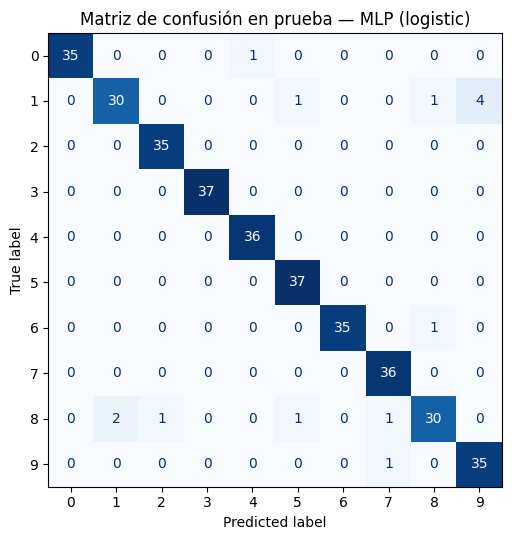

In [ ]:
fig, eje = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, cmap="Blues", ax=eje, colorbar=False)
eje.set_title(f"Matriz de confusión en prueba — MLP ({mejor_activacion})")
plt.tight_layout()
plt.show()

Errores en prueba: 14 de 360


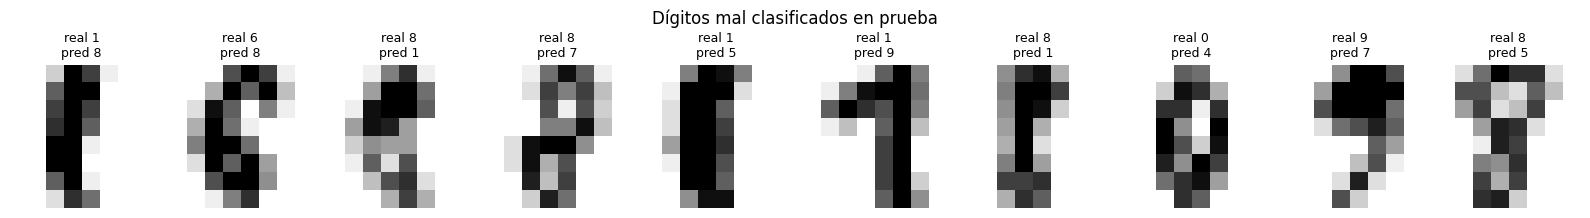

In [ ]:
errores = np.flatnonzero(y_pred_test != y_test)
print(f"Errores en prueba: {len(errores)} de {len(y_test)}")
if len(errores):
    n = min(10, len(errores))
    fig, ejes = plt.subplots(1, n, figsize=(1.6 * n, 2.3))
    ejes = np.atleast_1d(ejes)
    for eje, i in zip(ejes, errores[:n]):
        eje.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
        eje.set_title(f"real {y_test[i]}\npred {y_pred_test[i]}", fontsize=9)
        eje.axis("off")
    plt.suptitle("Dígitos mal clasificados en prueba")
    plt.tight_layout()
    plt.show()

## 8. Análisis de resultados y conclusión

*Las cifras citadas corresponden a la ejecución que quedó guardada en este cuaderno. Los tiempos dependen de la
máquina y pueden variar un poco al volver a ejecutar; las precisiones son reproducibles porque las semillas están fijas.*

### 8.1. Lo que observamos

| Activación | Accuracy val. (1 semilla) | Accuracy val. (media de 5 semillas) | Log loss val. | Iteraciones | Tiempo aprox. |
| --- | ---: | ---: | ---: | ---: | ---: |
| `identity` | 0,953 | 0,952 ± 0,005 | 0,502 | ~24 | ~0,04–0,05 s |
| `logistic` | **0,975** | **0,980 ± 0,005** | **0,104** | ~42–44 | ~0,09–0,10 s |
| `tanh` | 0,967 | 0,973 ± 0,002 | 0,135 | ~19–20 | ~0,04–0,05 s |
| `relu` | 0,961 | 0,969 ± 0,007 | 0,191 | ~22–23 | ~0,05–0,07 s |

1. **Los cuatro modelos convergieron** (ninguno agotó `max_iter=2000`) y entrenaron en **menos de una décima de segundo**.
   A diferencia del cuaderno de referencia (datos sintéticos 2D, donde `logistic` y `tanh` tardaron entre 14 y 23 s
   sin converger), aquí el costo computacional no es un factor decisivo: el conjunto es pequeño (1077 muestras de
   entrenamiento, 64 características) y las entradas están estandarizadas.
2. **`identity` ya alcanza ~95 %.** Es un modelo equivalente a uno lineal, así que los dígitos de 8×8 son
   *casi* linealmente separables. Sin embargo, su **log loss (0,50) es entre 2,5 y 5 veces peor** que el de las
   activaciones no lineales: acierta bastante, pero con probabilidades mucho menos fiables. Las activaciones no
   lineales aportan una mejora real, aunque modesta, en precisión y una mejora grande en calidad de las probabilidades.
3. **Entre las tres no lineales, `logistic` fue la mejor** en accuracy y en log loss, tanto con una semilla como en
   promedio de cinco. Es también la que más iteraciones necesita (~2× las otras), consistente con que la sigmoide
   satura y avanza más lento.
4. **Las diferencias entre `logistic`, `tanh` y `relu` son pequeñas.** Con 360 muestras de validación, una muestra
   equivale a 0,28 puntos porcentuales; la brecha entre `logistic` y `relu` equivale a unas 4–5 muestras y la desviación entre
   semillas es de 0,2–0,7 puntos. Es una ventaja consistente en nuestras pruebas, pero no es una prueba estadística
   de superioridad general.
5. **Sobreajuste.** Todos los modelos alcanzan 100 % de accuracy en entrenamiento y entre 95 % y 98 % en validación.
   Con 64 neuronas ocultas y pocas muestras, la red memoriza el entrenamiento. Una mayor regularización (`alpha`) o
   *early stopping* podrían reducir esa brecha.

### 8.2. Resultado final en prueba

La activación seleccionada por la regla fijada de antemano fue **`logistic`**. En el conjunto de prueba (360 imágenes
nunca usadas para decidir) obtuvo **accuracy = 0,961** (14 errores), frente a 0,10 de la referencia trivial.
Los dígitos más difíciles fueron el **1** (recall 0,83) y el **8** (recall 0,86), y la clase con menor precisión fue el
**9** (0,90); son formas que, con solo 8×8 píxeles, se confunden con facilidad entre sí. Los dígitos 3, 2, 4, 5 y 7
se reconocieron con recall de 1,00.

### 8.3. ¿Cuál conviene usar?

**Para este problema recomendamos `logistic`**, por tres razones: (i) obtuvo la mayor precisión y el menor log loss
en validación, de forma consistente con varias semillas; (ii) su desventaja de tiempo es solo **absoluta de
milisegundos** (~0,1 s frente a ~0,05 s), irrelevante en un conjunto de este tamaño; y (iii) esa diferencia de tiempo,
aunque sea de ~2× en términos relativos, no compensa perder precisión y calibración.

**Alternativa razonable: `tanh`.** Es prácticamente igual de rápida que `identity` y `relu`, y su precisión queda a menos
de un punto de `logistic`. Si el tiempo de entrenamiento fuera una restricción real, `tanh` sería el mejor
compromiso entre rapidez y precisión.

**Cuándo cambiaría la recomendación.** Con conjuntos de datos mucho mayores o redes más profundas, `relu` suele
ser la mejor opción: es barata de calcular, no satura para valores positivos y evita el gradiente que se desvanece
de `logistic` y `tanh`. En el cuaderno de referencia, con datos sintéticos y el mismo solver, `relu` fue por mucho
la más rápida y la mejor; aquí no se nota porque el problema es pequeño y fácil. Por último, **`identity` no es
recomendable** salvo como línea base: no puede representar fronteras no lineales y sus probabilidades son las peores.

**Limitaciones.** Se usó una sola arquitectura (una capa oculta de 64 neuronas) y un solo solver (`lbfgs`); los
tiempos dependen del solver, del hardware y de la implementación, y la conclusión sobre la mejor activación
podría cambiar con otra configuración. Una comparación más completa exploraría arquitecturas, valores de `alpha`
y otros solvers (`adam`, `sgd`) con validación cruzada.

## Referencias

- [`MLPClassifier`: parámetros, atributos y métodos](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).
- [Redes neuronales supervisadas (scikit-learn)](https://scikit-learn.org/stable/modules/neural_networks_supervised.html).
- [`load_digits`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).
- [Errores comunes: filtración de datos](https://scikit-learn.org/stable/common_pitfalls.html).
- Cuaderno de referencia del curso: `02_MLP_EZ_datos_sinteticos.ipynb`.